In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update(
    {
        "font.size": 10,
        "axes.titlesize": 14,
        "axes.labelsize": 10,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 10,
        # embed TrueType fonts in PDF for consistent rendering
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        # use Computer Modern (mathtext + serif fallback)
        "font.family": "serif",
        "font.serif": ["Computer Modern", "DejaVu Serif"],
        "mathtext.fontset": "cm",
        # avoid requiring an external TeX installation by using mathtext
        "text.usetex": False,
    }
)

In [2]:
import os

import jax
import jax.numpy as jnp

os.environ["CUDA_VISIBLE_DEVICES"] = "3"

HORIZON = 10
INITIAL_STATE = jnp.array([3.0, 5.0])  # position, velocity

In [3]:
from hcnn.training.train_bundle import TrainBundle

system = TrainBundle.build_double_integrator()

In [4]:
gain_matrix = jnp.array([[0.2, 2 / 3]])

In [5]:
from hcnn.optimization_layer import Rollout


def scan_fn(state, _):
    action = -gain_matrix @ state
    next_state = system.sys_dynamics(state, action)
    return next_state, (state, action)


states, actions = jax.lax.scan(scan_fn, INITIAL_STATE, None, length=HORIZON)[1]

raw_rollout = Rollout(states, actions)

In [6]:
raw_rollout

Rollout(states=Array([[ 3.        ,  5.        ],
       [ 6.0333333 ,  1.0666666 ],
       [ 6.141111  , -0.8511112 ],
       [ 4.959593  , -1.5119259 ],
       [ 3.455683  , -1.4958938 ],
       [ 2.112852  , -1.1897678 ],
       [ 1.1083883 , -0.81915975],
       [ 0.451443  , -0.4947309 ],
       [ 0.07647809, -0.2551989 ],
       [-0.10130231, -0.10036191]], dtype=float32), actions=Array([[-3.9333334 ],
       [-1.9177778 ],
       [-0.66081476],
       [ 0.0160321 ],
       [ 0.306126  ],
       [ 0.37060812],
       [ 0.32442886],
       [ 0.239532  ],
       [ 0.15483698],
       [ 0.0871684 ]], dtype=float32))

In [7]:
from hcnn.optimization_layer import ProjectionPhi, ProjectionProblem
from hcnn.solver import SQPParameters, sqp_solve

projection_problem = ProjectionProblem.factory(
    sys_dynamics=system.sys_dynamics,
    sys_constraints=system.sys_constraints,
    horizon=HORIZON,
)
phi = ProjectionPhi(
    states_ref=raw_rollout.states,
    actions_ref=raw_rollout.actions,
    initial_state=INITIAL_STATE,
)
sqp_parameters = SQPParameters(max_iter_nonlin=10, tol_prim=1e-6, tol_dual=1e-6)

In [8]:
def projector(phi):
    sqp_problem = projection_problem.replace(phi=phi)
    x_star, sqp_info = sqp_solve(sqp_problem, sqp_parameters)
    return sqp_problem.x_to_optvar(x_star), sqp_info


optvar, vjp_fun, sqp_info = jax.vjp(projector, phi, has_aux=True)
proj_rollout = Rollout(
    states=optvar.states,
    actions=optvar.actions,
)

osqp prim 6.258487701416016e-06, dual 1.71363335539354e-05, iter 2000, mult 0.00390625, infeas False
SQP iter 1/10 | beta: 1.000e+00 | lin iters: 2000
osqp prim 6.498380571429152e-07, dual 5.960434350527066e-07, iter 220, mult 16.0, infeas False
SQP iter 2/10 | beta: 1.000e+00 | lin iters: 220


In [9]:
sqp_info

SQPInfo(primal_residual=Array(9.536743e-07, dtype=float32), dual_residual=Array(5.9604344e-07, dtype=float32), iterations_lin=Array(1110., dtype=float32, weak_type=True), iterations_nonlin=Array(2, dtype=int32, weak_type=True), rho_base_mult=Array(8.001953, dtype=float32), converged_flag=Array(True, dtype=bool), avg_step_size=Array(1., dtype=float32, weak_type=True))

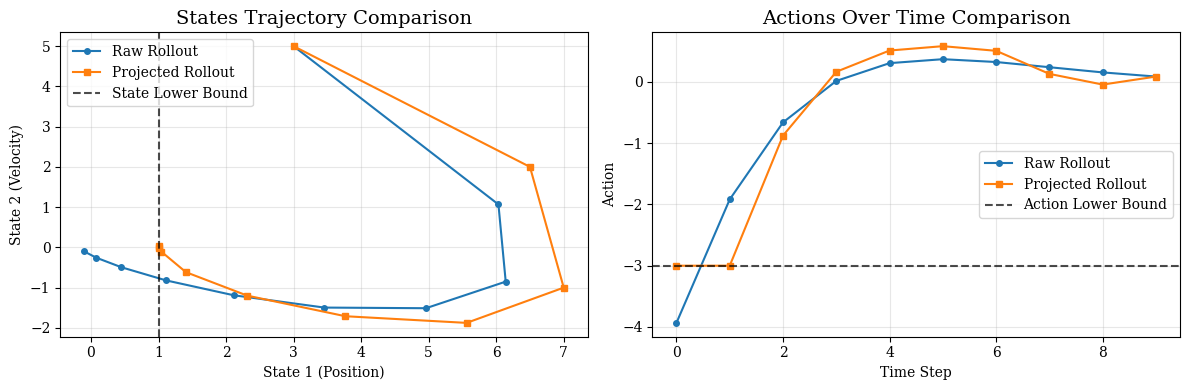

Trajectory Comparison Summary:
Max difference in states: 1.101302
Max difference in actions: 1.082223
Raw rollout actions outside bounds: 2
Projected rollout actions outside bounds: 2


In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Plot states comparison
ax1.plot(
    raw_rollout.states[:, 0],
    raw_rollout.states[:, 1],
    "o-",
    label="Raw Rollout",
    markersize=4,
    linewidth=1.5,
)
ax1.plot(
    proj_rollout.states[:, 0],
    proj_rollout.states[:, 1],
    "s-",
    label="Projected Rollout",
    markersize=4,
    linewidth=1.5,
)
ax1.axvline(
    x=1.0, color="k", linestyle="--", alpha=0.7, label="State Lower Bound"
)
ax1.set_xlabel("State 1 (Position)")
ax1.set_ylabel("State 2 (Velocity)")
ax1.set_title("States Trajectory Comparison")
ax1.legend(loc="upper left")
# ax1.axis("equal")
ax1.grid(True, alpha=0.3)

# Plot actions comparison
time_steps = range(len(raw_rollout.actions))
ax2.plot(
    time_steps,
    raw_rollout.actions[:, 0],
    "o-",
    label="Raw Rollout",
    markersize=4,
    linewidth=1.5,
)
ax2.plot(
    time_steps,
    proj_rollout.actions[:, 0],
    "s-",
    label="Projected Rollout",
    markersize=4,
    linewidth=1.5,
)
ax2.axhline(
    y=-3.0, color="k", linestyle="--", alpha=0.7, label="Action Lower Bound"
)
ax2.set_xlabel("Time Step")
ax2.set_ylabel("Action")
ax2.set_title("Actions Over Time Comparison")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print numerical comparison
print("Trajectory Comparison Summary:")
print(
    f"Max difference in states: {jnp.max(jnp.abs(raw_rollout.states - proj_rollout.states)):.6f}"
)
print(
    f"Max difference in actions: {jnp.max(jnp.abs(raw_rollout.actions - proj_rollout.actions)):.6f}"
)
print(
    f"Raw rollout actions outside bounds: {jnp.sum(jnp.abs(raw_rollout.actions) > 1.0)}"
)
print(
    f"Projected rollout actions outside bounds: {jnp.sum(jnp.abs(proj_rollout.actions) > 1.0)}"
)
fig.savefig("trajectory_comparison.pdf")

In [11]:
output_perturbation = jax.tree.map(jnp.zeros_like, optvar)
output_perturbation = output_perturbation.replace(
    states=jnp.array(
        [
            [0.0, 0.0],
            [0.0, 0.0],
            [0.0, 0.0],
            [0.0, 0.0],
            [0.0, 1.0],
            [0.0, 0.0],
            [0.0, 0.0],
            [0.0, 0.0],
            [0.0, 0.0],
            [0.0, 0.0],
        ]
    )
)
input_perturbation = vjp_fun(output_perturbation)

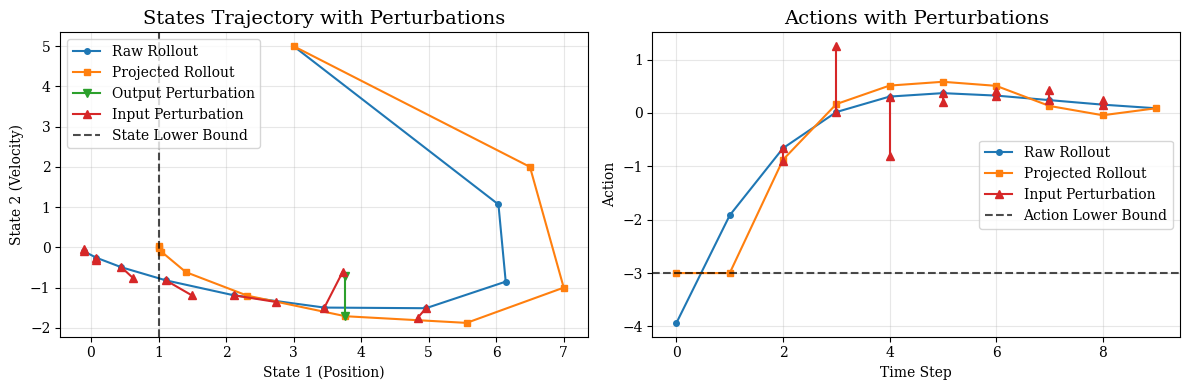

: 

In [ ]:
from matplotlib import pyplot as plt

# Extract input perturbation for easier access
input_pert = input_perturbation[0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Plot states comparison with arrows for input perturbations
ax1.plot(
    raw_rollout.states[:, 0],
    raw_rollout.states[:, 1],
    "o-",
    label="Raw Rollout",
    markersize=4,
    linewidth=1.5,
)
ax1.plot(
    proj_rollout.states[:, 0],
    proj_rollout.states[:, 1],
    "s-",
    label="Projected Rollout",
    markersize=4,
    linewidth=1.5,
)

# Find the state perturbation index
output_pert_state_idx = jnp.nonzero(
    jnp.abs(output_perturbation.states).sum(axis=1)
)[0][0]

# Add arrow for output perturbation at projected rollout state
if jnp.abs(output_perturbation.states[output_pert_state_idx]).max() > 1e-6:
    ax1.plot(
        [
            proj_rollout.states[output_pert_state_idx, 0],
            proj_rollout.states[output_pert_state_idx, 0]
            + output_perturbation.states[output_pert_state_idx, 0],
        ],
        [
            proj_rollout.states[output_pert_state_idx, 1],
            proj_rollout.states[output_pert_state_idx, 1]
            + output_perturbation.states[output_pert_state_idx, 1],
        ],
        "v-",
        color="C2",
        linewidth=1.5,
        label="Output Perturbation",
    )

# Add lines for significant input perturbations (states_ref) at raw rollout points
scale_factor = 5.0  # Scale arrows for visibility
input_pert_plotted = False
for i in range(len(raw_rollout.states)):
    if (
        jnp.abs(input_pert.states_ref[i]).max() > 5e-3
    ):  # Higher threshold for less clutter
        label = "Input Perturbation" if not input_pert_plotted else ""
        ax1.plot(
            [
                raw_rollout.states[i, 0],
                raw_rollout.states[i, 0]
                + input_pert.states_ref[i, 0] * scale_factor,
            ],
            [
                raw_rollout.states[i, 1],
                raw_rollout.states[i, 1]
                + input_pert.states_ref[i, 1] * scale_factor,
            ],
            "^-",
            color="C3",
            linewidth=1.5,
            label=label,
        )
        input_pert_plotted = True

ax1.axvline(
    x=1.0, color="k", linestyle="--", alpha=0.7, label="State Lower Bound"
)
ax1.set_xlabel("State 1 (Position)")
ax1.set_ylabel("State 2 (Velocity)")
ax1.set_title("States Trajectory with Perturbations")
ax1.legend()
# ax1.axis("equal")
ax1.grid(True, alpha=0.3)

# Plot actions comparison with lines for perturbations
time_steps = range(len(raw_rollout.actions))
ax2.plot(
    time_steps,
    raw_rollout.actions[:, 0],
    "o-",
    label="Raw Rollout",
    markersize=4,
    linewidth=1.5,
)
ax2.plot(
    time_steps,
    proj_rollout.actions[:, 0],
    "s-",
    label="Projected Rollout",
    markersize=4,
    linewidth=1.5,
)

# Add lines for significant input perturbations (actions_ref) at raw rollout points
input_pert_plotted_actions = False
for i in range(len(raw_rollout.actions)):
    if (
        jnp.abs(input_pert.actions_ref[i, 0]) > 5e-3
    ):  # Higher threshold for less clutter
        label = "Input Perturbation" if not input_pert_plotted_actions else ""
        ax2.plot(
            [i, i],
            [
                raw_rollout.actions[i, 0],
                raw_rollout.actions[i, 0]
                + input_pert.actions_ref[i, 0] * scale_factor,
            ],
            "^-",
            color="C3",
            linewidth=1.5,
            label=label,
        )
        input_pert_plotted_actions = True

ax2.axhline(
    y=-3.0, color="k", alpha=0.7, linestyle="--", label="Action Lower Bound"
)
ax2.set_xlabel("Time Step")
ax2.set_ylabel("Action")
ax2.set_title("Actions with Perturbations")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
fig.savefig("trajectory_perturbation.pdf")